# Nilgai YOLOv8 Nano - White-Hot Thermal Detection

**Dataset**: Synthetic white-hot thermal images  
**Model**: YOLOv8 Nano (`yolov8n.pt`)  
**Target**: Detect `nilgai` in thermal imagery  
**GPU**: RTX 5050 (`device=0`)

---

## Cell 1 — Install Ultralytics

In [ ]:
# Cell 1: Install Ultralytics
import sys
print('Python executable:', sys.executable)
!{sys.executable} -m pip install ultralytics --upgrade -q
print('Ultralytics installed/updated.')

## Cell 2 — Verify GPU & Imports

In [ ]:
# Cell 2: Verify GPU and Imports
import torch
from ultralytics import YOLO
import cv2
import numpy as np
import yaml
import shutil
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

print('PyTorch  :', torch.__version__)
print('CUDA     :', torch.version.cuda)
print('GPU avail:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name :', torch.cuda.get_device_name(0))
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM     : {total_vram:.1f} GB')

## Cell 3 — Diagnose Dataset (Images vs Labels)

In [ ]:
# Cell 3: Diagnose Dataset - Images vs Labels
DS_ROOT = Path(r'C:/Projects/mscSem3/Dataset/yolo_ds')
IMG_DIR = DS_ROOT / 'white_hot'   # white_hot_frame_XXXX.png
LBL_DIR = DS_ROOT / 'labels'      # frame_XXXX.txt

images = sorted(IMG_DIR.glob('*.png'))
labels = sorted(LBL_DIR.glob('*.txt'))
print(f'Images found : {len(images)}')
print(f'Labels found : {len(labels)}')
print()
print('Sample image name :', images[0].name)
print('Sample label name :', labels[0].name)
print()
print('Content of', labels[0].name, ':')
print(labels[0].read_text())

## Cell 4 — Build YOLO Dataset Structure (80/20 Split)

YOLO requires `images/train`, `images/val`, `labels/train`, `labels/val`.  
This cell also fixes the filename prefix mismatch between images and labels.

In [ ]:
# Cell 4: Build YOLO Dataset Structure with 80/20 Train-Val Split
# YOLO expects: images/train, images/val, labels/train, labels/val
# FIX: image prefix 'white_hot_frame_XXXX.png' -> label 'frame_XXXX.txt'

OUT_DS = DS_ROOT.parent / 'white_hot_yolo_ds'

for split in ['train', 'val']:
    (OUT_DS / 'images' / split).mkdir(parents=True, exist_ok=True)
    (OUT_DS / 'labels' / split).mkdir(parents=True, exist_ok=True)

# Pair each image with its matching label
pairs = []
for img_path in images:
    frame_id = img_path.stem.replace('white_hot_', '')  # e.g. frame_0000
    lbl_path = LBL_DIR / (frame_id + '.txt')
    if lbl_path.exists():
        pairs.append((img_path, lbl_path))
    else:
        print('WARNING: No label for', img_path.name)

print(f'Matched pairs: {len(pairs)} / {len(images)}')

# Shuffle and split
random.seed(42)
random.shuffle(pairs)
split_idx   = int(0.8 * len(pairs))
train_pairs = pairs[:split_idx]
val_pairs   = pairs[split_idx:]
print(f'Train: {len(train_pairs)} | Val: {len(val_pairs)}')

def copy_pairs(pair_list, split):
    img_out = OUT_DS / 'images' / split
    lbl_out = OUT_DS / 'labels' / split
    for img_path, lbl_path in pair_list:
        new_stem = img_path.stem.replace('white_hot_', '')
        shutil.copy2(img_path, img_out / (new_stem + '.png'))
        shutil.copy2(lbl_path, lbl_out / lbl_path.name)

copy_pairs(train_pairs, 'train')
copy_pairs(val_pairs,   'val')

n_tr_img = len(list((OUT_DS / 'images' / 'train').iterdir()))
n_vl_img = len(list((OUT_DS / 'images' / 'val').iterdir()))
print()
print('Dataset ready at:', OUT_DS)
print('  images/train :', n_tr_img, 'files')
print('  images/val   :', n_vl_img, 'files')

## Cell 5 — Create dataset.yaml

In [ ]:
# Cell 5: Create dataset.yaml
YAML_PATH = OUT_DS / 'dataset.yaml'

dataset_cfg = {
    'path' : str(OUT_DS).replace('\\', '/'),
    'train': 'images/train',
    'val'  : 'images/val',
    'nc'   : 1,
    'names': {0: 'nilgai'},
}

with open(YAML_PATH, 'w') as f:
    yaml.dump(dataset_cfg, f, default_flow_style=False, sort_keys=False)

print('dataset.yaml written to:', YAML_PATH)
print()
print('--- Content ---')
print(YAML_PATH.read_text())

## Cell 6 — Pre-Training Sanity Check

Verify images and bounding boxes are correctly aligned **before** training.

In [ ]:
# Cell 6: Pre-Training Sanity Check - Visualise Ground-Truth Boxes
CLASS_NAMES = ['nilgai']

def draw_yolo_boxes(img_path, lbl_path):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)
    with open(lbl_path) as f:
        for line in f.read().strip().splitlines():
            parts  = line.split()
            cls_id = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            x1 = (cx - bw / 2) * w
            y1 = (cy - bh / 2) * h
            rect = patches.Rectangle(
                (x1, y1), bw * w, bh * h,
                linewidth=2.5, edgecolor='lime', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(x1, y1 - 6, CLASS_NAMES[cls_id],
                    color='lime', fontsize=11, fontweight='bold',
                    bbox=dict(facecolor='black', alpha=0.5, pad=2))
    ax.set_title('Ground-Truth | ' + img_path.name, fontsize=13)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

sample_imgs = list((OUT_DS / 'images' / 'train').glob('*.png'))
sample_img  = random.choice(sample_imgs)
sample_lbl  = OUT_DS / 'labels' / 'train' / (sample_img.stem + '.txt')
draw_yolo_boxes(sample_img, sample_lbl)

## Cell 7 — Train YOLOv8 Nano (50 Epochs, GPU, auto-batch)

In [ ]:
# Cell 7: Train YOLOv8 Nano - 50 epochs, GPU device=0, batch=-1 (auto VRAM)
model = YOLO('yolov8n.pt')   # downloads pretrained nano weights on first run

results = model.train(
    data    = str(YAML_PATH),
    epochs  = 50,
    imgsz   = 640,
    device  = 0,        # RTX 5050
    batch   = -1,       # auto-detect max batch that fits in VRAM
    workers = 4,
    project = str(DS_ROOT.parent / 'runs'),
    name    = 'nilgai_white_hot_yolov8n',
    exist_ok= True,
    patience= 20,       # early-stop if no improvement for 20 epochs
    plots   = True,
    verbose = True,
)

print('Training complete!')
BEST_WEIGHTS = Path(results.save_dir) / 'weights' / 'best.pt'
print('Best weights:', BEST_WEIGHTS)

## Cell 8 — Validate on Val Set

In [ ]:
# Cell 8: Validate on Validation Set
best_model  = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(
    data   = str(YAML_PATH),
    device = 0,
    imgsz  = 640,
    split  = 'val',
)
print()
print('Validation Metrics:')
print(f'  mAP50    : {val_metrics.box.map50:.4f}')
print(f'  mAP50-95 : {val_metrics.box.map:.4f}')
print(f'  Precision: {val_metrics.box.mp:.4f}')
print(f'  Recall   : {val_metrics.box.mr:.4f}')

## Cell 9 — Inference on a Single Test Image

Run the trained model on a training image to verify it detects Nilgai.

In [ ]:
# Cell 9: Inference on a Single Test Image with Bounding Box Display
TEST_IMG = sample_imgs[0]   # first image from training set
print('Running inference on:', TEST_IMG.name)

preds = best_model.predict(
    source  = str(TEST_IMG),
    device  = 0,
    imgsz   = 640,
    conf    = 0.25,
    iou     = 0.45,
    save    = False,
    verbose = False,
)

result    = preds[0]
annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

orig = cv2.cvtColor(cv2.imread(str(TEST_IMG)), cv2.COLOR_BGR2RGB)
axes[0].imshow(orig)
axes[0].set_title('Original Image', fontsize=13)
axes[0].axis('off')

axes[1].imshow(annotated)
axes[1].set_title('YOLOv8n Prediction (Nilgai Detection)', fontsize=13)
axes[1].axis('off')

plt.suptitle('Inference | ' + TEST_IMG.name, fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

boxes = result.boxes
if len(boxes) == 0:
    print('No detections - try lowering conf threshold.')
else:
    print(f'{len(boxes)} detection(s):')
    for i, box in enumerate(boxes):
        cls  = int(box.cls[0])
        conf = float(box.conf[0])
        xyxy = [round(v, 1) for v in box.xyxy[0].tolist()]
        print(f'  [{i+1}] {CLASS_NAMES[cls]}  conf={conf:.3f}  bbox={xyxy}')

## Cell 10 — Display Training Curves

In [ ]:
# Cell 10: Display Training Curves
SAVE_DIR   = Path(results.save_dir)
plot_files = ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png']
available  = [SAVE_DIR / p for p in plot_files if (SAVE_DIR / p).exists()]

if not available:
    print('No plots found. Save dir:', SAVE_DIR)
else:
    fig, axes = plt.subplots(1, len(available), figsize=(7 * len(available), 6))
    if len(available) == 1:
        axes = [axes]
    for ax, pf in zip(axes, available):
        ax.imshow(cv2.cvtColor(cv2.imread(str(pf)), cv2.COLOR_BGR2RGB))
        ax.set_title(pf.name, fontsize=11)
        ax.axis('off')
    plt.suptitle('Training Diagnostics', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print('All outputs saved in:', SAVE_DIR)

## Cell 11 — Save All White-Hot Images with Ground-Truth Bounding Boxes

Draws GT boxes on **all 100** original `white_hot` images using OpenCV and saves them  
to `C:/Projects/mscSem3/Dataset/yolo_ds/white_hot_bounding_box/`.

Done! 100 images saved to: C:\Projects\mscSem3\Dataset\yolo_ds\white_hot_bounding_box
Skipped (no label): 0


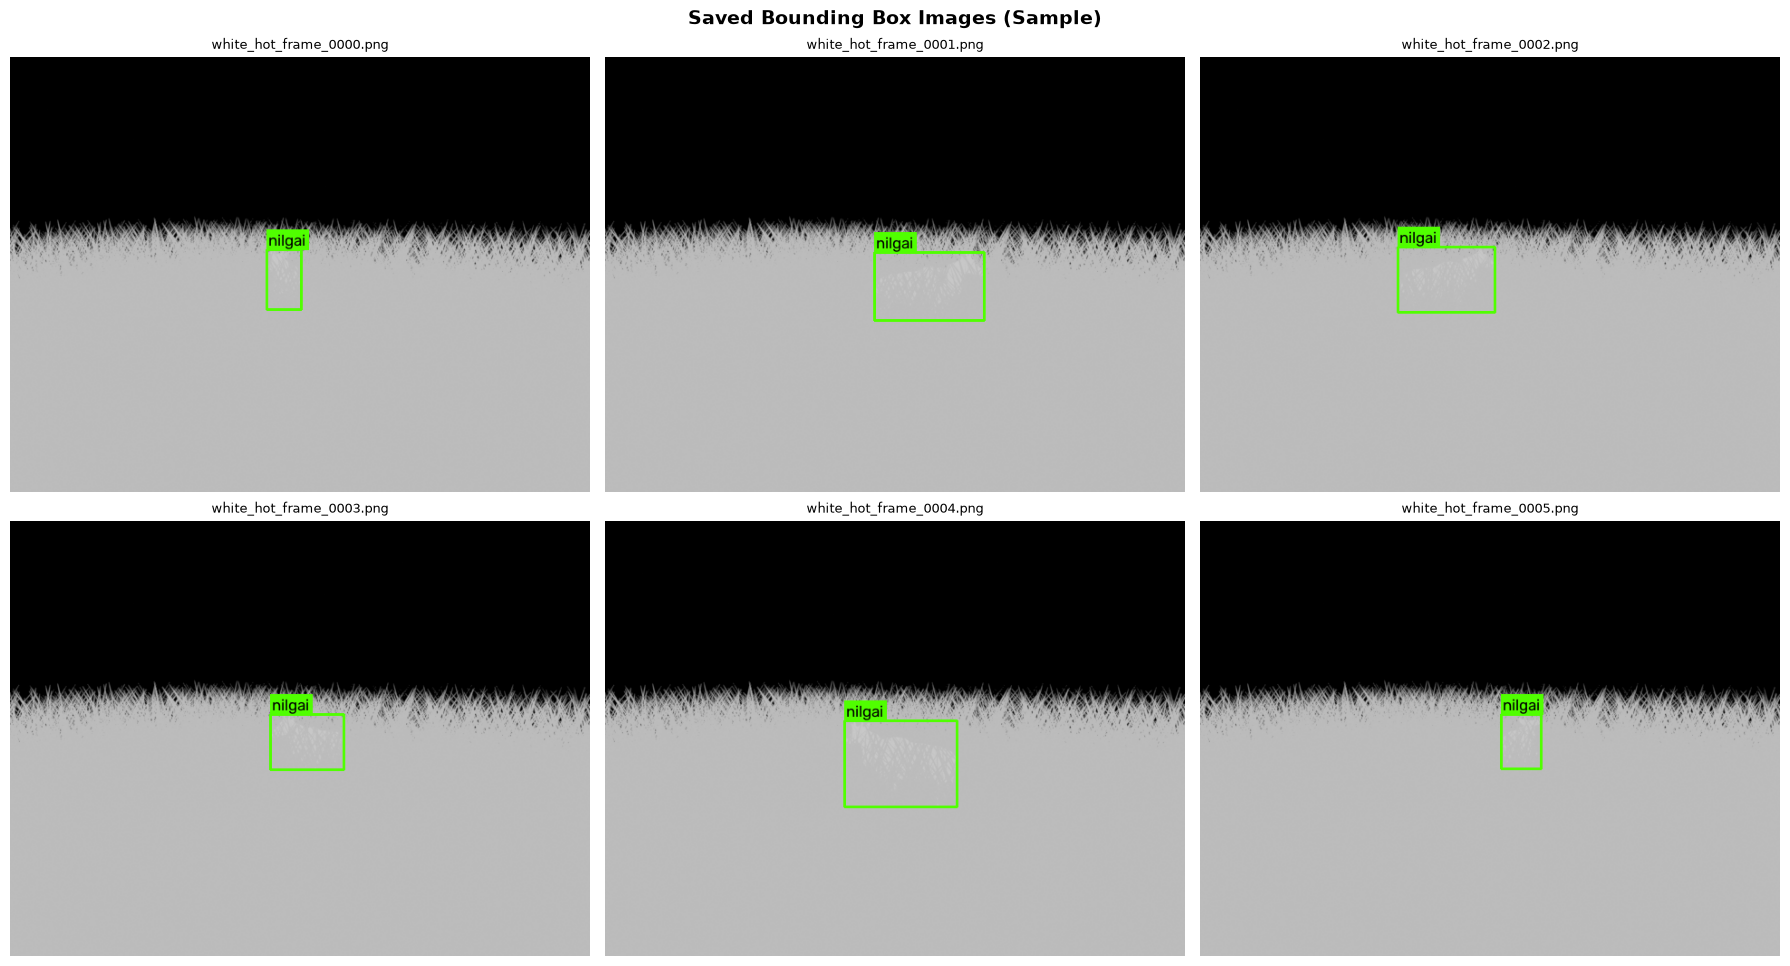

In [12]:
# Cell 11: Save ALL white_hot images with GT bounding boxes drawn on them
# Output folder: C:/Projects/mscSem3/Dataset/yolo_ds/white_hot_bounding_box

BB_OUT = Path(r'C:/Projects/mscSem3/Dataset/yolo_ds/white_hot_bounding_box')
BB_OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['nilgai']
BOX_COLOR   = (0, 255, 80)    # bright green (BGR)
TXT_COLOR   = (0, 255, 80)
THICKNESS   = 2
FONT        = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE  = 0.6

saved = 0
skipped = 0

# Iterate over ALL original white_hot images
all_imgs = sorted(Path(r'C:/Projects/mscSem3/Dataset/yolo_ds/white_hot').glob('*.png'))

for img_path in all_imgs:
    # Resolve matching label: white_hot_frame_XXXX -> frame_XXXX.txt
    frame_id = img_path.stem.replace('white_hot_', '')
    lbl_path = Path(r'C:/Projects/mscSem3/Dataset/yolo_ds/labels') / (frame_id + '.txt')

    if not lbl_path.exists():
        print('SKIP (no label):', img_path.name)
        skipped += 1
        continue

    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    with open(lbl_path) as f:
        for line in f.read().strip().splitlines():
            parts  = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id      = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)
            # Draw bounding box
            cv2.rectangle(img, (x1, y1), (x2, y2), BOX_COLOR, THICKNESS)
            # Draw label background + text
            label      = CLASS_NAMES[cls_id]
            (tw, th), _ = cv2.getTextSize(label, FONT, FONT_SCALE, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw + 4, y1), BOX_COLOR, -1)
            cv2.putText(img, label, (x1 + 2, y1 - 4), FONT, FONT_SCALE, (0, 0, 0), 1, cv2.LINE_AA)

    # Save with same filename into output folder
    out_path = BB_OUT / img_path.name
    cv2.imwrite(str(out_path), img)
    saved += 1

print(f'Done! {saved} images saved to: {BB_OUT}')
print(f'Skipped (no label): {skipped}')

# Show a sample grid (first 6 images)
sample_files = sorted(BB_OUT.glob('*.png'))[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, fp in zip(axes, sample_files):
    ax.imshow(cv2.cvtColor(cv2.imread(str(fp)), cv2.COLOR_BGR2RGB))
    ax.set_title(fp.name, fontsize=9)
    ax.axis('off')
for ax in axes[len(sample_files):]:
    ax.axis('off')
plt.suptitle('Saved Bounding Box Images (Sample)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## colormap genrate

✅ Image successfully saved to: C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot_frame_0000_with_colorbar.png


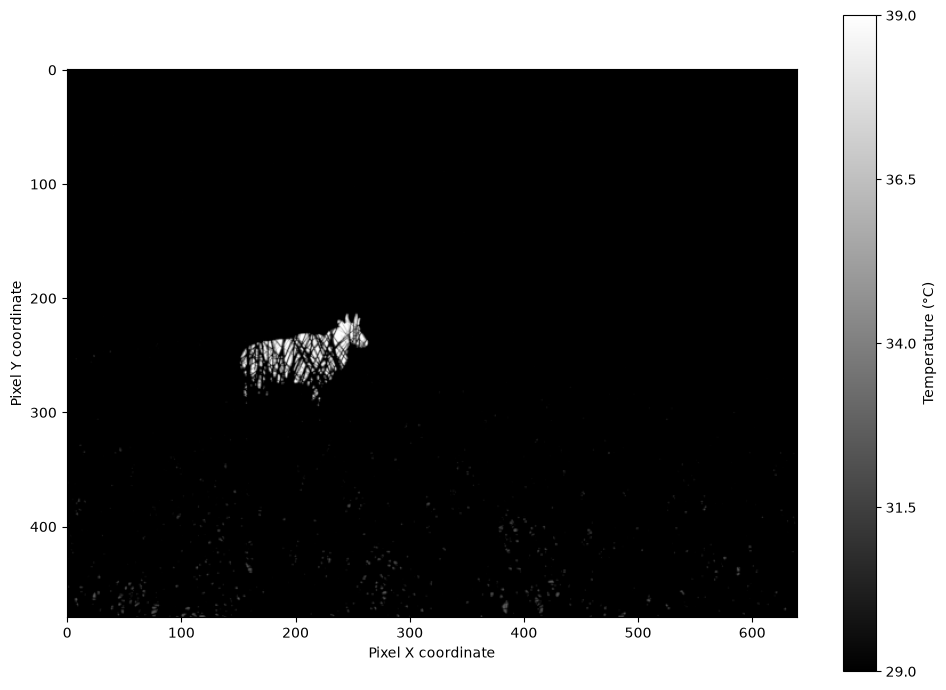

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Define your temperature variables
TA = 27.0  
TEMP_MAMMAL = TA + 12.0  # 39.0
TEMP_SOIL = TA + 3.0     # 30.0
TEMP_GRASS = TA + 2.0    # 29.0

# Calculate the window bounds for the colorbar
lo = min(TEMP_MAMMAL, TEMP_SOIL, TEMP_GRASS) # Bottom of colorbar (29.0)
hi = max(TEMP_MAMMAL, TEMP_SOIL, TEMP_GRASS) # Top of colorbar (39.0)

# 2. Load the exact image you specified
img_path = r"C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot\white_hot_frame_0000.png"
img = mpimg.imread(img_path)

# Ensure it is treated as a single-channel grayscale image
if len(img.shape) == 3:
    img_gray = img[:, :, 0]
else:
    img_gray = img

# 3. Create the plot
fig, ax = plt.subplots(figsize=(10, 7))

# Draw the image mapping pixel value 0.0 to 'lo' and 1.0 to 'hi'
cax = ax.imshow(img_gray, cmap='gray', vmin=0, vmax=1)

# Add and format the colorbar
cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Temperature (°C)')

# Distribute the temperature ticks evenly across the bar
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels([
    f"{lo:.1f}", 
    f"{lo + (hi-lo)*0.25:.1f}", 
    f"{lo + (hi-lo)*0.5:.1f}", 
    f"{lo + (hi-lo)*0.75:.1f}", 
    f"{hi:.1f}"
])

ax.set_xlabel('Pixel X coordinate')
ax.set_ylabel('Pixel Y coordinate')

plt.tight_layout()

# 4. Save the figure to your folder BEFORE showing it
save_path = r"C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot_frame_0000_with_colorbar.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

print(f"✅ Image successfully saved to: {save_path}")

# Display it in the notebook
plt.show()